# Proyek Analisis Data: Bike Sharing Dataset

**Nama:** `[Mufid Dhamarjati Kusuma]`  
**Email:** `[mufiddmrjt@gmail.com]`  
**ID Dicoding:** `[ds297b6y1042]`

Dataset yang digunakan adalah **Bike Sharing Dataset** yang berisi catatan penyewaan sepeda Capital Bikeshare di Washington, D.C., Amerika Serikat. Berdasarkan `Readme.txt`, data mencakup periode 2011–2012 dan disediakan dalam dua tingkat agregasi: harian (`data/data_1.csv`, salinan `day.csv`) dan per jam (`data/data_2.csv`, salinan `hour.csv`).

Tujuan proyek ini adalah memahami pola permintaan penyewaan sepeda menurut waktu, jenis hari, musim, dan kondisi cuaca, lalu menyusun rekomendasi operasional berdasarkan temuan yang benar-benar didukung data.

## Menentukan Pertanyaan Bisnis

Pertanyaan bisnis dirumuskan menggunakan kerangka **SMART**:

- **Specific (Spesifik):** fokus pada topik, kelompok, dan variabel yang jelas.
- **Measurable (Terukur):** dapat dijawab dengan ukuran kuantitatif, misalnya rata-rata jumlah penyewaan.
- **Action-Oriented (Berorientasi Aksi):** hasilnya dapat diterjemahkan menjadi tindakan operasional.
- **Relevant (Relevan):** berhubungan dengan pengelolaan layanan penyewaan sepeda.
- **Time-bound (Terikat Waktu):** memiliki periode analisis yang tegas.

### Pertanyaan 1

**Bagaimana perbedaan rata-rata jumlah penyewaan sepeda pada setiap jam antara hari kerja (*working day*) dan hari bukan hari kerja (*non-working day*) selama 1 Januari 2011–31 Desember 2012, dan pada jam berapa permintaan rata-rata mencapai puncaknya untuk masing-masing jenis hari?**

Penerapan SMART:

- **Specific:** membandingkan pola penyewaan per jam pada hari kerja dan bukan hari kerja.
- **Measurable:** rata-rata jumlah penyewaan (`cnt`) untuk setiap jam (`hr`) pada masing-masing kelompok hari.
- **Action-Oriented:** membantu menentukan waktu prioritas untuk distribusi dan ketersediaan armada.
- **Relevant:** pola waktu permintaan penting untuk perencanaan operasional layanan bike sharing.
- **Time-bound:** 1 Januari 2011–31 Desember 2012.

**Data utama:** `hour.csv`; metrik utama: rata-rata `cnt` per jam.

### Pertanyaan 2

**Bagaimana perbedaan rata-rata jumlah penyewaan sepeda harian berdasarkan kategori musim (`season`) dan kondisi cuaca (`weathersit`) selama 1 Januari 2011–31 Desember 2012, serta kategori mana yang memiliki rata-rata penyewaan tertinggi dan terendah?**

Penerapan SMART:

- **Specific:** membandingkan penyewaan harian menurut kategori musim dan cuaca.
- **Measurable:** rata-rata jumlah penyewaan harian (`cnt`) pada setiap kategori, disertai jumlah observasi.
- **Action-Oriented:** menjadi masukan untuk perencanaan kapasitas armada dan penjadwalan promosi.
- **Relevant:** musim dan cuaca merupakan konteks lingkungan yang berkaitan dengan permintaan layanan sepeda.
- **Time-bound:** 1 Januari 2011–31 Desember 2012.

**Data utama:** `day.csv`; metrik utama: rata-rata `cnt` per kategori musim dan cuaca.

> Catatan: analisis ini bersifat deskriptif dan menunjukkan pola/asosiasi. Hasilnya tidak dengan sendirinya membuktikan hubungan sebab-akibat.

## Import Semua Packages/Library yang Digunakan

In [1]:
# Pengolahan data
import os
from pathlib import Path
import warnings

import numpy as np
import pandas as pd

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Seaborn:", sns.__version__)

Pandas: 3.0.1
NumPy: 2.4.2
Seaborn: 0.13.2


## Data Wrangling

### Gathering Data

#### 1. Gathering data: memuat data harian dan per jam dari folder data/.
Struktur submission:

data/data_1.csv = salinan day.csv

data/data_2.csv = salinan hour.csv

Fallback juga disediakan untuk nama file sumber ketika notebook dipindahkan.

In [2]:
def locate_or_upload(project_filename, original_filename):
    candidates = [
        Path("data") / project_filename,
        Path(project_filename),
        Path(original_filename),
        Path.cwd() / "data" / project_filename,
        Path.cwd() / project_filename,
        Path("/mnt/data") / original_filename,
        Path("/content") / project_filename,
        Path("/content") / original_filename,
    ]
    for candidate in candidates:
        if candidate.exists():
            print(f"File ditemukan: {candidate.resolve()}")
            return candidate

    try:
        from google.colab import files
        print(f"Silakan unggah {project_filename} (atau {original_filename}).")
        uploaded = files.upload()
        if project_filename in uploaded:
            return Path(project_filename)
        if original_filename in uploaded:
            return Path(original_filename)
        raise FileNotFoundError(
            f"Unggah file bernama {project_filename} atau {original_filename}."
        )
    except ImportError as exc:
        raise FileNotFoundError(
            f"File {project_filename} tidak ditemukan. Pastikan folder data/ "
            "berisi data_1.csv dan data_2.csv, atau letakkan file CSV di folder notebook."
        ) from exc


day_path = locate_or_upload("data_1.csv", "day.csv")
hour_path = locate_or_upload("data_2.csv", "hour.csv")

day_raw = pd.read_csv(day_path)
hour_raw = pd.read_csv(hour_path)

print("Data harian (data_1.csv):", day_raw.shape)
print("Data per jam (data_2.csv):", hour_raw.shape)
print("Rentang tanggal harian:", day_raw["dteday"].min(), "s.d.", day_raw["dteday"].max())
print("Rentang tanggal per jam:", hour_raw["dteday"].min(), "s.d.", hour_raw["dteday"].max())

display(day_raw.head())
display(hour_raw.head())

File ditemukan: C:\Users\hp\Documents\Bike-Sharing-Analytics-Dashboard\data\data_1.csv
File ditemukan: C:\Users\hp\Documents\Bike-Sharing-Analytics-Dashboard\data\data_2.csv
Data harian (data_1.csv): (731, 16)
Data per jam (data_2.csv): (17379, 17)
Rentang tanggal harian: 2011-01-01 s.d. 2012-12-31
Rentang tanggal per jam: 2011-01-01 s.d. 2012-12-31


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.20,0.21,0.59,0.16,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.23,0.23,0.44,0.19,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.29,0.75,0.00,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.29,0.75,0.00,0,1,1


**Insight — Gathering Data**

- `data_1.csv` memuat **731 baris dan 16 kolom** untuk agregasi harian.
- `data_2.csv` memuat **17.379 baris dan 17 kolom** untuk agregasi per jam.
- Keduanya mencakup **1 Januari 2011 sampai 31 Desember 2012**.
- Kedua tingkat agregasi dipertahankan: data harian digunakan untuk musim/cuaca, sedangkan data per jam digunakan untuk pola waktu. Ini menghindari pencampuran metrik harian dan per jam.

### Assessing Data

#### 2. Memeriksa struktur kolom, tipe data, dan jumlah observasi.

In [3]:
print("Informasi day.csv")
day_raw.info()
print("\nInformasi hour.csv")
hour_raw.info()

print("\nKolom day.csv:", day_raw.columns.tolist())
print("Kolom hour.csv:", hour_raw.columns.tolist())

Informasi day.csv
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

Informasi hour.csv
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data 

#### 3. Memeriksa missing value pada setiap kolom.

In [4]:
missing_summary = pd.DataFrame({
    "day_missing": day_raw.isna().sum(),
    "hour_missing": hour_raw.isna().sum()
}).fillna(0).astype(int)

display(missing_summary)
print("Total missing day.csv :", int(day_raw.isna().sum().sum()))
print("Total missing hour.csv:", int(hour_raw.isna().sum().sum()))

,day_missing,hour_missing
atemp,0,0
casual,0,0
cnt,0,0
dteday,0,0
holiday,0,0
hr,0,0
hum,0,0
instant,0,0
mnth,0,0
registered,0,0


Total missing day.csv : 0
Total missing hour.csv: 0


#### 4. Memeriksa duplikasi baris dan duplikasi nilai primary key instant.

In [5]:
duplicate_summary = pd.DataFrame({
    "dataset": ["day.csv", "hour.csv"],
    "duplicate_rows": [day_raw.duplicated().sum(), hour_raw.duplicated().sum()],
    "duplicate_instant": [day_raw["instant"].duplicated().sum(), hour_raw["instant"].duplicated().sum()]
})
display(duplicate_summary)

,dataset,duplicate_rows,duplicate_instant
0,day.csv,0,0
1,hour.csv,0,0


#### 5. Memeriksa rentang nilai dan kategori pada kolom kategorikal/indikator.

In [6]:
category_columns = ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]
if "hr" in hour_raw.columns:
    category_columns.append("hr")

for column in category_columns:
    source = hour_raw if column == "hr" else day_raw
    print(f"{column}: {sorted(source[column].dropna().unique().tolist())}")

print("\nRentang numerik day.csv:")
display(day_raw.describe().T)
print("\nRentang numerik hour.csv:")
display(hour_raw.describe().T)

# Memeriksa kode kategori di luar rentang yang dijelaskan dalam Readme.txt.
allowed_categories = {
    "season": {1, 2, 3, 4}, "yr": {0, 1}, "mnth": set(range(1, 13)),
    "holiday": {0, 1}, "weekday": set(range(0, 7)),
    "workingday": {0, 1}, "weathersit": {1, 2, 3, 4},
}
invalid_category_rows = []
for dataset_name, df in [("day.csv", day_raw), ("hour.csv", hour_raw)]:
    for column, allowed in allowed_categories.items():
        invalid_count = int((~df[column].isin(allowed)).sum())
        invalid_category_rows.append({"dataset": dataset_name, "column": column, "invalid_rows": invalid_count})
    if "hr" in df.columns:
        invalid_category_rows.append({"dataset": dataset_name, "column": "hr", "invalid_rows": int((~df["hr"].isin(set(range(24)))).sum())})
display(pd.DataFrame(invalid_category_rows))

season: [1, 2, 3, 4]
yr: [0, 1]
mnth: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
holiday: [0, 1]
weekday: [0, 1, 2, 3, 4, 5, 6]
workingday: [0, 1]
weathersit: [1, 2, 3]
hr: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]

Rentang numerik day.csv:


,count,mean,std,min,25%,50%,75%,max
instant,731.00,366.00,211.17,1.00,183.50,366.00,548.50,731.00
season,731.00,2.50,1.11,1.00,2.00,3.00,3.00,4.00
yr,731.00,0.50,0.50,0.00,0.00,1.00,1.00,1.00
mnth,731.00,6.52,3.45,1.00,4.00,7.00,10.00,12.00
holiday,731.00,0.03,0.17,0.00,0.00,0.00,0.00,1.00
weekday,731.00,3.00,2.00,0.00,1.00,3.00,5.00,6.00
workingday,731.00,0.68,0.47,0.00,0.00,1.00,1.00,1.00
weathersit,731.00,1.40,0.54,1.00,1.00,1.00,2.00,3.00
temp,731.00,0.50,0.18,0.06,0.34,0.50,0.66,0.86
atemp,731.00,0.47,0.16,0.08,0.34,0.49,0.61,0.84



Rentang numerik hour.csv:


,count,mean,std,min,25%,50%,75%,max
instant,"17,379.00","8,690.00","5,017.03",1.00,"4,345.50","8,690.00","13,034.50","17,379.00"
season,"17,379.00",2.50,1.11,1.00,2.00,3.00,3.00,4.00
yr,"17,379.00",0.50,0.50,0.00,0.00,1.00,1.00,1.00
mnth,"17,379.00",6.54,3.44,1.00,4.00,7.00,10.00,12.00
hr,"17,379.00",11.55,6.91,0.00,6.00,12.00,18.00,23.00
holiday,"17,379.00",0.03,0.17,0.00,0.00,0.00,0.00,1.00
weekday,"17,379.00",3.00,2.01,0.00,1.00,3.00,5.00,6.00
workingday,"17,379.00",0.68,0.47,0.00,0.00,1.00,1.00,1.00
weathersit,"17,379.00",1.43,0.64,1.00,1.00,1.00,2.00,4.00
temp,"17,379.00",0.50,0.19,0.02,0.34,0.50,0.66,1.00


,dataset,column,invalid_rows
0,day.csv,season,0
1,day.csv,yr,0
2,day.csv,mnth,0
3,day.csv,holiday,0
4,day.csv,weekday,0
5,day.csv,workingday,0
6,day.csv,weathersit,0
7,hour.csv,season,0
8,hour.csv,yr,0
9,hour.csv,mnth,0


#### 6. Memeriksa kesesuaian tanggal dengan kolom tahun, bulan, dan weekday.
Dalam dataset ini weekday menggunakan konvensi Minggu=0, Senin=1, ..., Sabtu=6.

In [7]:

def date_consistency_report(df, dataset_name):
    dates = pd.to_datetime(df["dteday"], errors="coerce")
    expected_weekday_sunday_zero = (dates.dt.dayofweek + 1) % 7
    report = {
        "dataset": dataset_name,
        "invalid_date": int(dates.isna().sum()),
        "year_mismatch": int(((dates.dt.year - 2011) != df["yr"]).sum()),
        "month_mismatch": int((dates.dt.month != df["mnth"]).sum()),
        "weekday_mismatch_sunday_zero": int((expected_weekday_sunday_zero != df["weekday"]).sum()),
    }
    return report

consistency_dates = pd.DataFrame([
    date_consistency_report(day_raw, "day.csv"),
    date_consistency_report(hour_raw, "hour.csv")
])
display(consistency_dates)

,dataset,invalid_date,year_mismatch,month_mismatch,weekday_mismatch_sunday_zero
0,day.csv,0,0,0,0
1,hour.csv,0,0,0,0


#### 7. Memeriksa konsistensi total penyewaan dan workingday.
nilai negatif, dan beberapa rentang indikator.

In [8]:
def value_consistency_report(df, dataset_name):
    numeric = df.select_dtypes(include=np.number)
    return {
        "dataset": dataset_name,
        "cnt_mismatch": int((df["cnt"] != df["casual"] + df["registered"]).sum()),
        "negative_numeric_cells": int((numeric < 0).sum().sum()),
        "temp_out_of_0_1": int((~df["temp"].between(0, 1)).sum()),
        "atemp_out_of_0_1": int((~df["atemp"].between(0, 1)).sum()),
        "hum_out_of_0_1": int((~df["hum"].between(0, 1)).sum()),
        "windspeed_out_of_0_1": int((~df["windspeed"].between(0, 1)).sum()),
    }

value_checks = pd.DataFrame([
    value_consistency_report(day_raw, "day.csv"),
    value_consistency_report(hour_raw, "hour.csv")
])
display(value_checks)

# Memeriksa konsistensi workingday.
# Definisi README: workingday=1 jika bukan akhir pekan dan bukan hari libur.
# weekday menggunakan Minggu=0 dan Sabtu=6.
def workingday_mismatch_count(df):
    expected_workingday = ((~df["weekday"].isin([0, 6])) & (df["holiday"] == 0)).astype(int)
    return int((expected_workingday != df["workingday"]).sum())

print("Mismatch workingday day.csv :", workingday_mismatch_count(day_raw))
print("Mismatch workingday hour.csv:", workingday_mismatch_count(hour_raw))

,dataset,cnt_mismatch,negative_numeric_cells,temp_out_of_0_1,atemp_out_of_0_1,hum_out_of_0_1,windspeed_out_of_0_1
0,day.csv,0,0,0,0,0,0
1,hour.csv,0,0,0,0,0,0


Mismatch workingday day.csv : 0
Mismatch workingday hour.csv: 0


#### 8. Memeriksa kelengkapan catatan per jam dan rekonsiliasi total harian.

In [9]:
hourly_coverage = (
    hour_raw.groupby("dteday")["hr"]
    .agg(observed_hours="nunique", min_hour="min", max_hour="max")
    .reset_index()
)
coverage_distribution = hourly_coverage["observed_hours"].value_counts().sort_index()

print("Distribusi jumlah jam yang tercatat per tanggal:")
display(coverage_distribution.rename_axis("observed_hours").reset_index(name="number_of_dates"))
print("Jumlah tanggal:", hourly_coverage.shape[0])
print("Tanggal dengan 24 jam tercatat:", int((hourly_coverage["observed_hours"] == 24).sum()))
print("Tanggal dengan kurang dari 24 jam:", int((hourly_coverage["observed_hours"] < 24).sum()))
print("Slot jam yang tidak tercatat dibanding 731 x 24:", 731 * 24 - len(hour_raw))

# Membandingkan jumlah penyewaan harian dengan penjumlahan data per jam.
hourly_daily_totals = hour_raw.groupby("dteday", as_index=False)["cnt"].sum()
hourly_daily_totals = hourly_daily_totals.rename(columns={"cnt": "cnt_from_hourly"})
comparison_daily_hourly = day_raw[["dteday", "cnt"]].merge(
    hourly_daily_totals, on="dteday", how="outer", indicator=True
)
comparison_daily_hourly["difference"] = (
    comparison_daily_hourly["cnt"] - comparison_daily_hourly["cnt_from_hourly"]
)
print("Tanggal yang tidak cocok status merge:", int((comparison_daily_hourly["_merge"] != "both").sum()))
print("Tanggal dengan total berbeda:", int((comparison_daily_hourly["difference"] != 0).sum()))
print("Total cnt day.csv :", int(day_raw["cnt"].sum()))
print("Total cnt hour.csv:", int(hour_raw["cnt"].sum()))

Distribusi jumlah jam yang tercatat per tanggal:


,observed_hours,number_of_dates
0,1,1
1,8,1
2,11,1
3,12,1
4,16,1
5,17,1
6,18,2
7,22,6
8,23,62
9,24,655


Jumlah tanggal: 731
Tanggal dengan 24 jam tercatat: 655
Tanggal dengan kurang dari 24 jam: 76
Slot jam yang tidak tercatat dibanding 731 x 24: 165
Tanggal yang tidak cocok status merge: 0
Tanggal dengan total berbeda: 0
Total cnt day.csv : 3292679
Total cnt hour.csv: 3292679


#### 9. Mengidentifikasi outlier dengan aturan IQR (1.5 x IQR).
Flag outlier hanya untuk pemeriksaan; tidak langsung menghapus observasi.

In [10]:
def iqr_outlier_summary(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)
    return {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": int(mask.sum()),
        "outlier_percent": float(mask.mean() * 100),
    }

outlier_summary = pd.DataFrame([
    {"dataset": "day.csv", "column": "cnt", **iqr_outlier_summary(day_raw["cnt"])},
    {"dataset": "hour.csv", "column": "cnt", **iqr_outlier_summary(hour_raw["cnt"])},
    {"dataset": "day.csv", "column": "casual", **iqr_outlier_summary(day_raw["casual"])},
    {"dataset": "hour.csv", "column": "casual", **iqr_outlier_summary(hour_raw["casual"])},
])
display(outlier_summary)

,dataset,column,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percent
0,day.csv,cnt,"3,152.00","5,956.00","2,804.00","-1,054.00","10,162.00",0,0.00
1,hour.csv,cnt,40.00,281.00,241.00,-321.50,642.50,505,2.91
2,day.csv,casual,315.50,"1,096.00",780.50,-855.25,"2,266.75",44,6.02
3,hour.csv,casual,4.00,48.00,44.00,-62.00,114.00,1192,6.86


**Insight — Assessing Data**

- Kedua dataset tidak memiliki *missing value*, baris duplikat, atau `instant` duplikat.
- Tidak ditemukan kategori di luar rentang yang dijelaskan README, tanggal tidak valid, ketidaksesuaian tahun/bulan/hari, nilai negatif, maupun ketidaksesuaian `cnt = casual + registered`.
- Pada data per jam, **76 tanggal** memiliki kurang dari 24 catatan; total ada **165 slot jam yang tidak tercatat**. Slot yang hilang tidak boleh dianggap sebagai jumlah penyewaan nol.
- Aturan IQR menandai sebagian nilai `cnt` per jam sebagai nilai ekstrem. Flag ini menjadi bahan peninjauan, bukan bukti bahwa datanya salah.
- `weathersit = 4` tidak muncul pada data harian, sehingga kategori tersebut tidak dapat dibandingkan pada agregasi harian.

### Cleaning Data

#### 10. Cleaning: membuat salinan data dan mengubah dteday menjadi datetime.
Tidak ada baris yang dihapus karena pemeriksaan tidak menunjukkan missing value, duplikasi, atau nilai negatif. Kolom asli tetap dipertahankan.

In [11]:
day_df = day_raw.copy()
hour_df = hour_raw.copy()

day_df["dteday"] = pd.to_datetime(day_df["dteday"], errors="coerce")
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"], errors="coerce")

# Memastikan konversi tanggal berhasil.
assert day_df["dteday"].notna().all()
assert hour_df["dteday"].notna().all()

print("Tipe data dteday day_df :", day_df["dteday"].dtype)
print("Tipe data dteday hour_df:", hour_df["dteday"].dtype)

Tipe data dteday day_df : datetime64[us]
Tipe data dteday hour_df: datetime64[us]


#### 11. Menambahkan label kategori berdasarkan keterangan pada Readme.txt.
Kolom kode asli (`season` dan `weathersit`) tetap dipertahankan untuk analisis, sedangkan label tambahan menggunakan nama kategori agar tabel, grafik, dan kesimpulan mudah dibaca. Kode musim 1 ditampilkan sebagai **Spring** (ejaan kategori yang dimaksud dalam README).


In [12]:
season_labels = {
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter",
}
weather_labels = {
    1: "Clear / Few clouds",
    2: "Mist + Cloudy",
    3: "Light Snow / Light Rain / Thunderstorm",
    4: "Heavy Rain / Snow / Fog",
}
workingday_labels = {0: "Bukan hari kerja", 1: "Hari kerja"}

def add_category_labels(df):
    df["season_label"] = df["season"].map(season_labels).fillna("Tidak diketahui")
    df["weather_label"] = df["weathersit"].map(weather_labels).fillna("Tidak diketahui")
    df["workingday_label"] = df["workingday"].map(workingday_labels).fillna("Tidak diketahui")
    df["year_label"] = df["yr"].map({0: "2011", 1: "2012"}).fillna("Tidak diketahui")
    return df

day_df = add_category_labels(day_df)
hour_df = add_category_labels(hour_df)

# Fitur waktu tambahan untuk kebutuhan EDA/visualisasi.
day_df["year_month"] = day_df["dteday"].dt.to_period("M").astype(str)
hour_df["year_month"] = hour_df["dteday"].dt.to_period("M").astype(str)

print("Label kategori berhasil ditambahkan.")
print("Label musim:", list(season_labels.values()))
print("Label cuaca:", list(weather_labels.values()))


Label kategori berhasil ditambahkan.
Label musim: ['Spring', 'Summer', 'Fall', 'Winter']
Label cuaca: ['Clear / Few clouds', 'Mist + Cloudy', 'Light Snow / Light Rain / Thunderstorm', 'Heavy Rain / Snow / Fog']


#### 12. Validasi ulang setelah cleaning.

In [13]:
cleaning_validation = pd.DataFrame([
    {
        "dataset": "day_df",
        "rows_before": len(day_raw),
        "rows_after": len(day_df),
        "missing_after": int(day_df.isna().sum().sum()),
        "duplicate_rows_after": int(day_df.duplicated().sum()),
        "cnt_mismatch_after": int((day_df["cnt"] != day_df["casual"] + day_df["registered"]).sum()),
    },
    {
        "dataset": "hour_df",
        "rows_before": len(hour_raw),
        "rows_after": len(hour_df),
        "missing_after": int(hour_df.isna().sum().sum()),
        "duplicate_rows_after": int(hour_df.duplicated().sum()),
        "cnt_mismatch_after": int((hour_df["cnt"] != hour_df["casual"] + hour_df["registered"]).sum()),
    },
])
display(cleaning_validation)

assert len(day_df) == len(day_raw)
assert len(hour_df) == len(hour_raw)
assert (day_df["cnt"] == day_df["casual"] + day_df["registered"]).all()
assert (hour_df["cnt"] == hour_df["casual"] + hour_df["registered"]).all()

,dataset,rows_before,rows_after,missing_after,duplicate_rows_after,cnt_mismatch_after
0,day_df,731,731,0,0,0
1,hour_df,17379,17379,0,0,0


#### 13. Menyimpan ringkasan keputusan cleaning agar transparan.

In [14]:
cleaning_decisions = pd.DataFrame([
    ["Missing value", "Tidak ditemukan pada kedua dataset", "Tidak perlu imputasi/penghapusan"],
    ["Duplicate", "Tidak ditemukan baris duplikat atau instant duplikat", "Tidak ada baris yang dihapus"],
    ["Tipe tanggal", "dteday awalnya bertipe object", "Dikonversi menjadi datetime"],
    ["Rentang jam", "76 tanggal memiliki kurang dari 24 jam tercatat", "Tidak mengisi slot yang hilang dengan nol"],
    ["Outlier", "Sebagian cnt per jam ter-flag oleh aturan IQR", "Dipertahankan; perlu konteks, bukan otomatis dihapus"],
    ["Label kategori", "Kode kategori mengikuti Readme.txt", "Label ditambahkan tanpa mengubah kode asli"],
], columns=["temuan", "hasil_assessment", "tindakan_cleaning"])
display(cleaning_decisions)

,temuan,hasil_assessment,tindakan_cleaning
0,Missing value,Tidak ditemukan pada kedua dataset,Tidak perlu imputasi/penghapusan
1,Duplicate,Tidak ditemukan baris duplikat atau instant du...,Tidak ada baris yang dihapus
2,Tipe tanggal,dteday awalnya bertipe object,Dikonversi menjadi datetime
3,Rentang jam,76 tanggal memiliki kurang dari 24 jam tercatat,Tidak mengisi slot yang hilang dengan nol
4,Outlier,Sebagian cnt per jam ter-flag oleh aturan IQR,"Dipertahankan; perlu konteks, bukan otomatis d..."
5,Label kategori,Kode kategori mengikuti Readme.txt,Label ditambahkan tanpa mengubah kode asli



### Menyimpan Dataset Hasil Data Wrangling untuk Dashboard

Dataset harian yang sudah melalui proses cleaning dan penambahan label kategori disimpan secara otomatis sebagai `dashboard/main_data.csv`. File ini digunakan oleh aplikasi Streamlit.

In [15]:

# Menyiapkan dan menyimpan data harian hasil Data Wrangling untuk dashboard.
dashboard_df = day_df.copy()

# Menambahkan kolom tahun dan periode bulan.
dashboard_df["year"] = dashboard_df["yr"].map({
    0: 2011,
    1: 2012
})
dashboard_df["year_month"] = dashboard_df["dteday"].dt.to_period("M").astype(str)

# Membuat folder dashboard jika belum tersedia.
project_dir = Path.cwd()
dashboard_dir = project_dir / "dashboard"
dashboard_dir.mkdir(parents=True, exist_ok=True)

# Menyimpan dataset menjadi CSV.
main_data_path = dashboard_dir / "main_data.csv"
dashboard_df.to_csv(main_data_path, index=False)

# Memeriksa hasil penyimpanan.
main_data_check = pd.read_csv(main_data_path, parse_dates=["dteday"])

print("main_data.csv berhasil dibuat!")
print(f"Lokasi file: {main_data_path.resolve()}")
print(f"Jumlah baris: {len(main_data_check)}")
print(f"Jumlah kolom: {len(main_data_check.columns)}")

display(main_data_check.head())

main_data.csv berhasil dibuat!
Lokasi file: C:\Users\hp\Documents\Bike-Sharing-Analytics-Dashboard\dashboard\main_data.csv
Jumlah baris: 731
Jumlah kolom: 22


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_label,weather_label,workingday_label,year_label,year_month,year
0,1,2011-01-01,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,331,654,985,Spring,Mist + Cloudy,Bukan hari kerja,2011,2011-01,2011
1,2,2011-01-02,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,131,670,801,Spring,Mist + Cloudy,Bukan hari kerja,2011,2011-01,2011
2,3,2011-01-03,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,120,1229,1349,Spring,Clear / Few clouds,Hari kerja,2011,2011-01,2011
3,4,2011-01-04,1,0,1,0,2,1,1,0.20,0.21,0.59,0.16,108,1454,1562,Spring,Clear / Few clouds,Hari kerja,2011,2011-01,2011
4,5,2011-01-05,1,0,1,0,3,1,1,0.23,0.23,0.44,0.19,82,1518,1600,Spring,Clear / Few clouds,Hari kerja,2011,2011-01,2011


**Insight - Cleaning Data dan Ringkasan Data Wrangling**

Kedua file berhasil dimuat. Tidak ditemukan missing value atau duplikasi sehingga tidak diperlukan imputasi maupun penghapusan baris. Kolom `dteday` diubah dari `object` menjadi `datetime`, dan label kategori ditambahkan berdasarkan pemetaan pada `Readme.txt` tanpa mengubah kode aslinya. Pada `hour.csv`, slot jam yang tidak tercatat tidak diisi dengan nol. Outlier IQR dipertahankan karena nilai ekstrem dapat merepresentasikan permintaan aktual.

Kualitas data setelah cleaning divalidasi kembali: jumlah baris tetap sama, missing value tetap nol, duplikasi tetap nol, dan persamaan `cnt = casual + registered` tetap terpenuhi. Konvensi `weekday` mengikuti dataset, yaitu Minggu=0 sampai Sabtu=6. Pemetaan musim/cuaca mengikuti README dan tidak ditafsirkan ulang secara diam-diam.

## Exploratory Data Analysis (EDA)

### Explore

In [16]:
# Ringkasan statistik untuk kedua tingkat agregasi.
print("Statistik data harian")
display(day_df[["casual", "registered", "cnt", "temp", "atemp", "hum", "windspeed"]].describe().T)

print("Statistik data per jam")
display(hour_df[["casual", "registered", "cnt", "temp", "atemp", "hum", "windspeed"]].describe().T)

print("Rentang tanggal day_df:", day_df["dteday"].min().date(), "s.d.", day_df["dteday"].max().date())
print("Rentang tanggal hour_df:", hour_df["dteday"].min().date(), "s.d.", hour_df["dteday"].max().date())

Statistik data harian


,count,mean,std,min,25%,50%,75%,max
casual,731.00,848.18,686.62,2.00,315.50,713.00,"1,096.00","3,410.00"
registered,731.00,"3,656.17","1,560.26",20.00,"2,497.00","3,662.00","4,776.50","6,946.00"
cnt,731.00,"4,504.35","1,937.21",22.00,"3,152.00","4,548.00","5,956.00","8,714.00"
temp,731.00,0.50,0.18,0.06,0.34,0.50,0.66,0.86
atemp,731.00,0.47,0.16,0.08,0.34,0.49,0.61,0.84
hum,731.00,0.63,0.14,0.00,0.52,0.63,0.73,0.97
windspeed,731.00,0.19,0.08,0.02,0.13,0.18,0.23,0.51


Statistik data per jam


,count,mean,std,min,25%,50%,75%,max
casual,"17,379.00",35.68,49.31,0.00,4.00,17.00,48.00,367.00
registered,"17,379.00",153.79,151.36,0.00,34.00,115.00,220.00,886.00
cnt,"17,379.00",189.46,181.39,1.00,40.00,142.00,281.00,977.00
temp,"17,379.00",0.50,0.19,0.02,0.34,0.50,0.66,1.00
atemp,"17,379.00",0.48,0.17,0.00,0.33,0.48,0.62,1.00
hum,"17,379.00",0.63,0.19,0.00,0.48,0.63,0.78,1.00
windspeed,"17,379.00",0.19,0.12,0.00,0.10,0.19,0.25,0.85


Rentang tanggal day_df: 2011-01-01 s.d. 2012-12-31
Rentang tanggal hour_df: 2011-01-01 s.d. 2012-12-31


#### EDA untuk Pertanyaan 1: rata-rata penyewaan setiap jam menurut jenis hari.

In [17]:
hourly_pattern = (
    hour_df.groupby(["workingday_label", "hr"], as_index=False)
    .agg(
        avg_rentals=("cnt", "mean"),
        median_rentals=("cnt", "median"),
        observations=("cnt", "size")
    )
)
hourly_pattern["avg_rentals"] = hourly_pattern["avg_rentals"].round(2)
display(hourly_pattern.head(12))

peak_by_day_type = hourly_pattern.loc[
    hourly_pattern.groupby("workingday_label")["avg_rentals"].idxmax()
].sort_values("workingday_label")
print("Jam dengan rata-rata penyewaan tertinggi per jenis hari:")
display(peak_by_day_type)

,workingday_label,hr,avg_rentals,median_rentals,observations
0,Bukan hari kerja,0,90.80,93.50,230
1,Bukan hari kerja,1,69.51,71.00,230
2,Bukan hari kerja,2,53.17,54.00,228
3,Bukan hari kerja,3,25.78,25.00,227
4,Bukan hari kerja,4,8.26,7.00,227
5,Bukan hari kerja,5,8.69,7.00,222
6,Bukan hari kerja,6,18.74,16.00,229
7,Bukan hari kerja,7,43.41,39.00,231
8,Bukan hari kerja,8,105.65,94.00,231
9,Bukan hari kerja,9,171.62,170.00,231


Jam dengan rata-rata penyewaan tertinggi per jenis hari:


,workingday_label,hr,avg_rentals,median_rentals,observations
13,Bukan hari kerja,13,372.73,367.00,231
41,Hari kerja,17,525.29,539.00,499


#### EDA untuk Pertanyaan 2: agregasi menurut musim dan cuaca.

In [18]:
season_summary = (
    day_df.groupby(["season", "season_label"], as_index=False)
    .agg(avg_rentals=("cnt", "mean"), median_rentals=("cnt", "median"), days=("cnt", "size"))
    .sort_values("season")
)
weather_summary = (
    day_df.groupby(["weathersit", "weather_label"], as_index=False)
    .agg(avg_rentals=("cnt", "mean"), median_rentals=("cnt", "median"), days=("cnt", "size"))
    .sort_values("weathersit")
)

print("Rata-rata penyewaan berdasarkan musim:")
display(season_summary[["season_label", "avg_rentals", "median_rentals", "days"]].round(2))
print("Rata-rata penyewaan berdasarkan kondisi cuaca:")
display(weather_summary[["weather_label", "avg_rentals", "median_rentals", "days"]].round(2))


Rata-rata penyewaan berdasarkan musim:


,season_label,avg_rentals,median_rentals,days
0,Spring,"2,604.13","2,209.00",181
1,Summer,"4,992.33","4,941.50",184
2,Fall,"5,644.30","5,353.50",188
3,Winter,"4,728.16","4,634.50",178


Rata-rata penyewaan berdasarkan kondisi cuaca:


,weather_label,avg_rentals,median_rentals,days
0,Clear / Few clouds,"4,876.79","4,844.00",463
1,Mist + Cloudy,"4,035.86","4,040.00",247
2,Light Snow / Light Rain / Thunderstorm,"1,803.29","1,817.00",21


#### EDA tambahan: perkembangan penyewaan per bulan dan komposisi tipe pengguna.

In [19]:
monthly_summary = (
    day_df.groupby("year_month", as_index=False)
    .agg(total_rentals=("cnt", "sum"), avg_daily_rentals=("cnt", "mean"))
)
user_summary = pd.DataFrame({
    "user_type": ["Casual", "Registered"],
    "rentals": [day_df["casual"].sum(), day_df["registered"].sum()]
})
user_summary["share_percent"] = user_summary["rentals"] / user_summary["rentals"].sum() * 100

year_summary = day_df.groupby("yr", as_index=False).agg(
    total_rentals=("cnt", "sum"), average_daily_rentals=("cnt", "mean"), days=("cnt", "size")
)
year_summary["year"] = year_summary["yr"].map({0: 2011, 1: 2012})

display(monthly_summary.head())
display(user_summary.round(2))
display(year_summary.round(2))

,year_month,total_rentals,avg_daily_rentals
0,2011-01,38189,"1,231.90"
1,2011-02,48215,"1,721.96"
2,2011-03,64045,"2,065.97"
3,2011-04,94870,"3,162.33"
4,2011-05,135821,"4,381.32"


,user_type,rentals,share_percent
0,Casual,620017,18.83
1,Registered,2672662,81.17


,yr,total_rentals,average_daily_rentals,days,year
0,0,1243103,"3,405.76",365,2011
1,1,2049576,"5,599.93",366,2012


### Insight:

- Dataset harian memiliki 731 observasi, sedangkan dataset per jam memiliki 17.379 observasi. Keduanya mencakup 1 Januari 2011 sampai 31 Desember 2012.
- Total penyewaan pada `day.csv` dan penjumlahan `hour.csv` dapat dibandingkan per tanggal untuk memeriksa konsistensi agregasi.
- Analisis berdasarkan jam menggunakan catatan yang tersedia. Karena terdapat tanggal yang tidak memiliki 24 catatan jam, hasil per jam perlu dibaca sebagai rata-rata dari observasi yang tercatat, bukan hasil imputasi untuk seluruh slot waktu.
- Rata-rata per kategori perlu dibaca bersama jumlah observasinya, terutama untuk kategori cuaca yang jarang muncul.

## Visualization & Explanatory Analysis

### Pertanyaan 1:
Visualisasi 1: pola rata-rata penyewaan berdasarkan jam pada dua jenis hari.

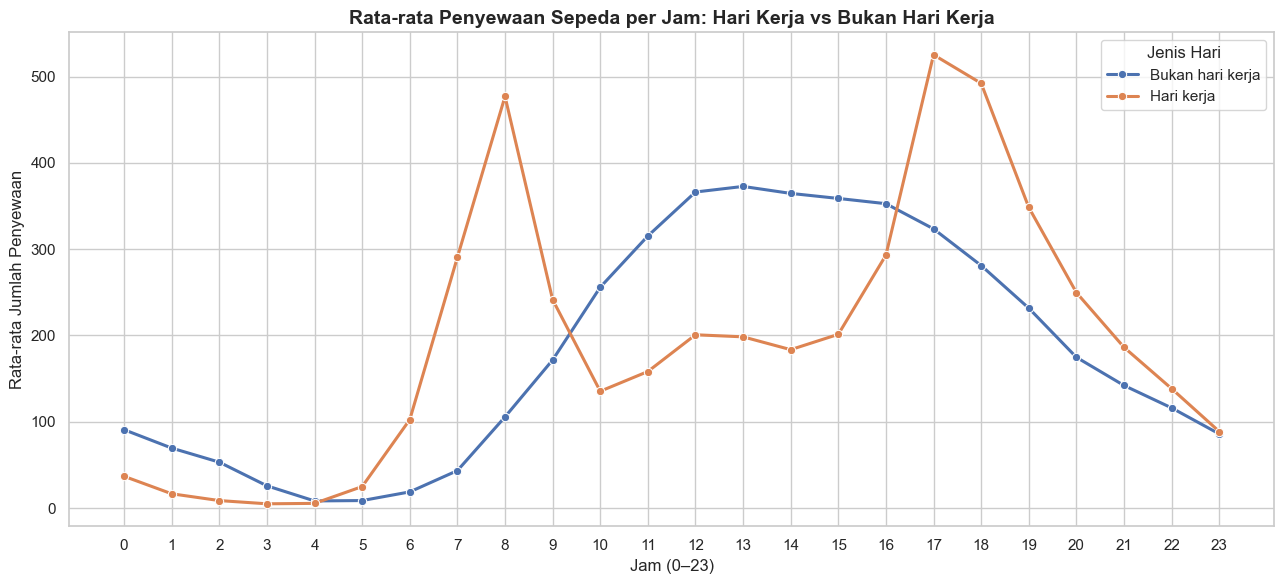

In [20]:

plt.figure(figsize=(13, 6))
sns.lineplot(
    data=hourly_pattern,
    x="hr",
    y="avg_rentals",
    hue="workingday_label",
    marker="o",
    linewidth=2.2
)
plt.title("Rata-rata Penyewaan Sepeda per Jam: Hari Kerja vs Bukan Hari Kerja", fontsize=14, weight="bold")
plt.xlabel("Jam (0–23)")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.xticks(range(24))
plt.legend(title="Jenis Hari")
plt.tight_layout()
plt.show()

Menampilkan jam puncak dalam tabel agar hasil grafik dapat dibaca secara kuantitatif.

In [21]:
peak_table = peak_by_day_type[["workingday_label", "hr", "avg_rentals", "observations"]].copy()
peak_table = peak_table.rename(columns={
    "workingday_label": "jenis_hari",
    "hr": "jam_puncak",
    "avg_rentals": "rata_rata_penyewaan",
    "observations": "jumlah_observasi"
})
display(peak_table)

,jenis_hari,jam_puncak,rata_rata_penyewaan,jumlah_observasi
13,Bukan hari kerja,13,372.73,231
41,Hari kerja,17,525.29,499


### Pertanyaan 2:
Visualisasi 2: perbandingan rata-rata penyewaan berdasarkan musim dan cuaca.

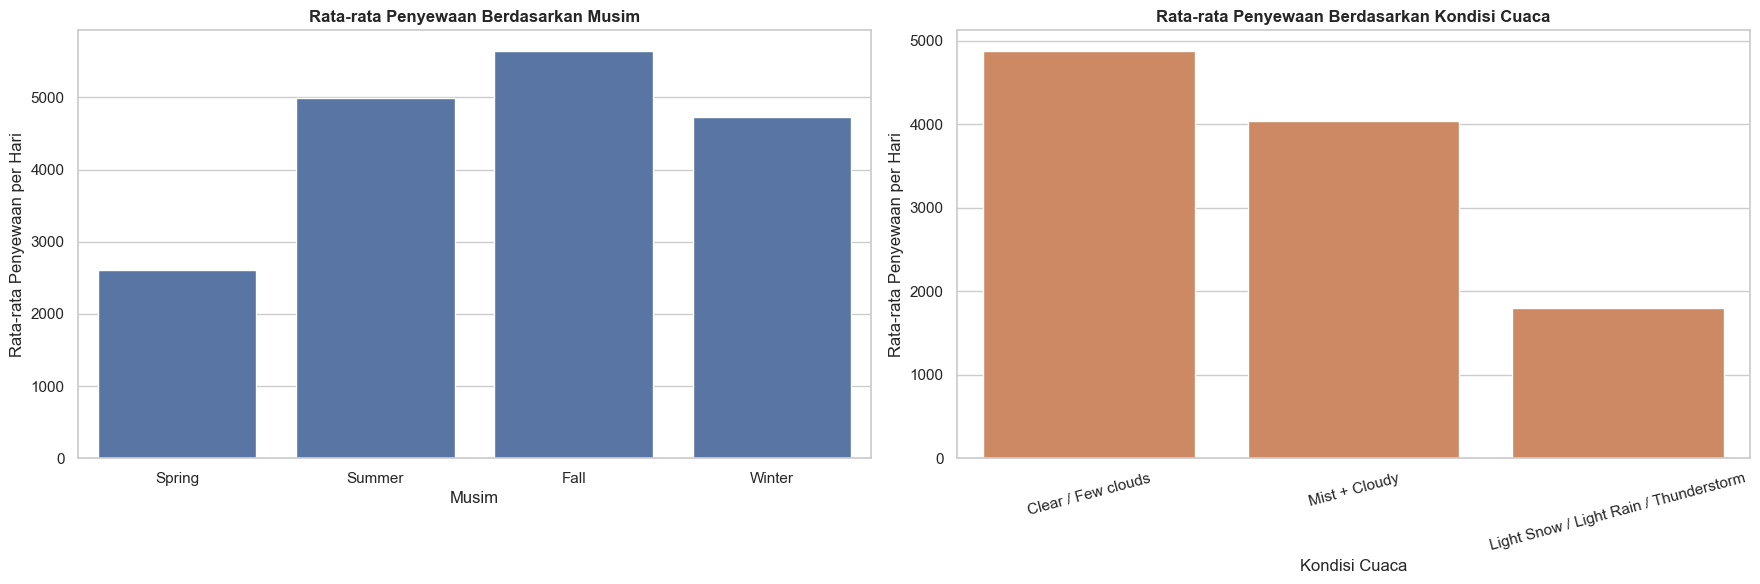

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(
    data=season_summary,
    x="season_label",
    y="avg_rentals",
    ax=axes[0],
    color=sns.color_palette("deep")[0],
    ci=None
)
axes[0].set_title("Rata-rata Penyewaan Berdasarkan Musim", weight="bold")
axes[0].set_xlabel("Musim")
axes[0].set_ylabel("Rata-rata Penyewaan per Hari")
axes[0].tick_params(axis="x", rotation=0)

sns.barplot(
    data=weather_summary,
    x="weather_label",
    y="avg_rentals",
    ax=axes[1],
    color=sns.color_palette("deep")[1],
    ci=None
)
axes[1].set_title("Rata-rata Penyewaan Berdasarkan Kondisi Cuaca", weight="bold")
axes[1].set_xlabel("Kondisi Cuaca")
axes[1].set_ylabel("Rata-rata Penyewaan per Hari")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


Memperjelas jumlah hari/observasi pada setiap kategori.

In [23]:
print("Jumlah observasi dan rata-rata per musim:")
display(season_summary[["season_label", "days", "avg_rentals"]].round(2))
print("Jumlah observasi dan rata-rata per kondisi cuaca:")
display(weather_summary[["weather_label", "days", "avg_rentals"]].round(2))


Jumlah observasi dan rata-rata per musim:


,season_label,days,avg_rentals
0,Spring,181,"2,604.13"
1,Summer,184,"4,992.33"
2,Fall,188,"5,644.30"
3,Winter,178,"4,728.16"


Jumlah observasi dan rata-rata per kondisi cuaca:


,weather_label,days,avg_rentals
0,Clear / Few clouds,463,"4,876.79"
1,Mist + Cloudy,247,"4,035.86"
2,Light Snow / Light Rain / Thunderstorm,21,"1,803.29"


### Insight:

**Interpretasi pertanyaan 1:** bandingkan posisi puncak kedua garis. Puncak hari kerja menunjukkan waktu yang perlu diperhatikan untuk mobilitas rutin, sedangkan puncak pada bukan hari kerja menunjukkan waktu dengan aktivitas penyewaan yang lebih terkonsentrasi pada siang hari. Rata-rata dihitung dari observasi per jam yang tersedia.

**Interpretasi pertanyaan 2:** rata-rata penyewaan harian tertinggi di antara kategori musim terdapat pada **Fall**, sedangkan yang terendah terdapat pada **Spring**. Berdasarkan cuaca, rata-rata tertinggi terdapat pada **Clear / Few clouds**, sedangkan terendah pada **Light Snow / Light Rain / Thunderstorm**. Jumlah observasi perlu diperhatikan karena kategori cuaca dengan kondisi lebih buruk memiliki jumlah hari yang jauh lebih sedikit. Temuan ini bersifat deskriptif dan tidak membuktikan sebab-akibat.


## Analisis Lanjutan

Analisis tambahan 1: tren rata-rata penyewaan harian per bulan.

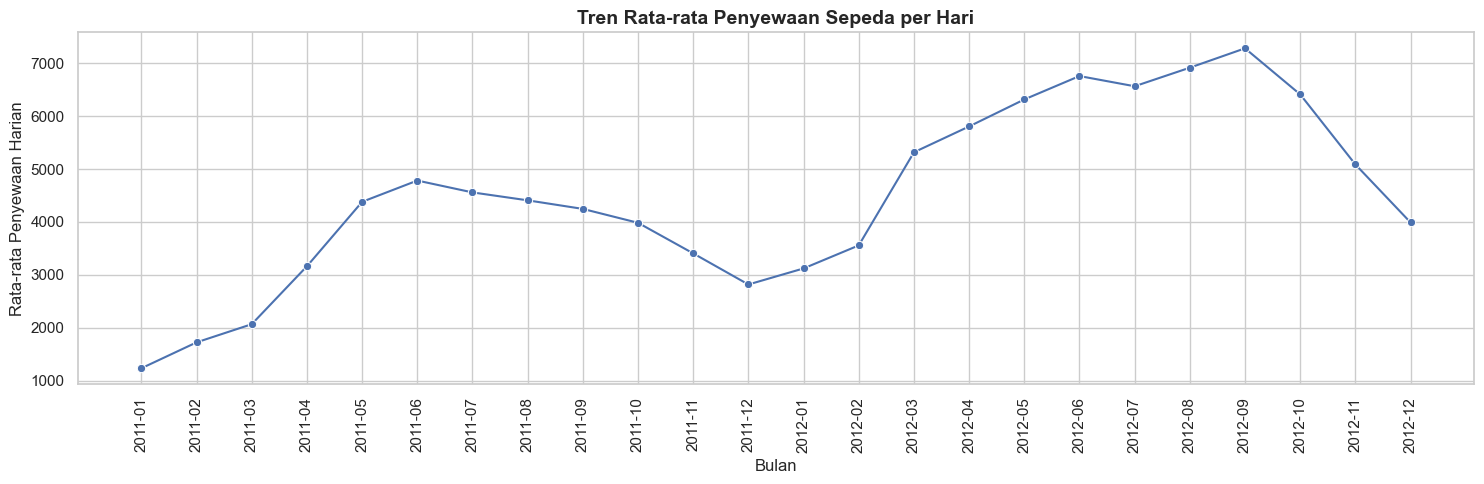

In [24]:
plt.figure(figsize=(15, 5))
sns.lineplot(data=monthly_summary, x="year_month", y="avg_daily_rentals", marker="o")
plt.title("Tren Rata-rata Penyewaan Sepeda per Hari", fontsize=14, weight="bold")
plt.xlabel("Bulan")
plt.ylabel("Rata-rata Penyewaan Harian")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Analisis tambahan 2: jumlah penyewaan berdasarkan tipe pengguna.


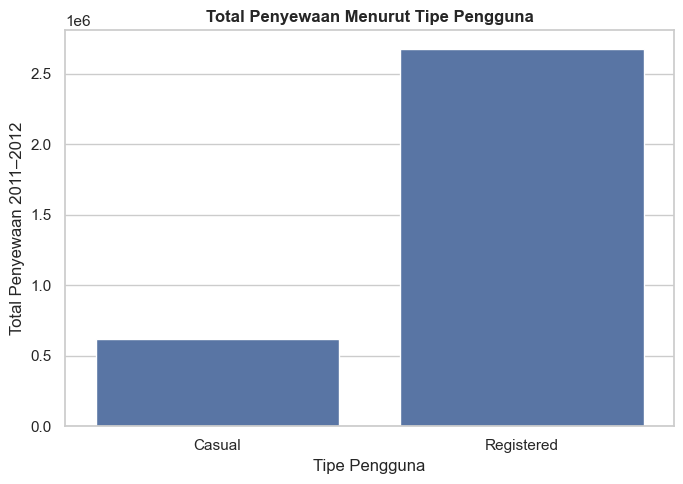

,user_type,rentals,share_percent
0,Casual,620017,18.83
1,Registered,2672662,81.17


In [25]:
plt.figure(figsize=(7, 5))
sns.barplot(data=user_summary, x="user_type", y="rentals", color=sns.color_palette("deep")[0])
plt.title("Total Penyewaan Menurut Tipe Pengguna", weight="bold")
plt.xlabel("Tipe Pengguna")
plt.ylabel("Total Penyewaan 2011–2012")
plt.tight_layout()
plt.show()
display(user_summary.round(2))

Analisis tambahan 3: perbandingan total dan rata-rata penyewaan antara 2011 dan 2012.

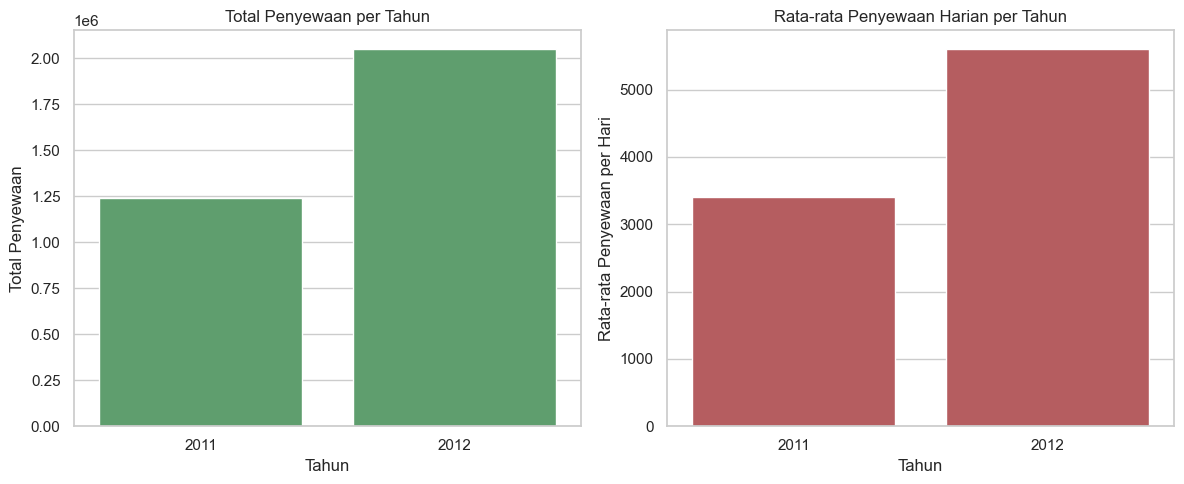

,year,total_rentals,average_daily_rentals,days
0,2011,1243103,"3,405.76",365
1,2012,2049576,"5,599.93",366


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(data=year_summary, x="year", y="total_rentals", ax=axes[0], color=sns.color_palette("deep")[2])
axes[0].set_title("Total Penyewaan per Tahun")
axes[0].set_xlabel("Tahun")
axes[0].set_ylabel("Total Penyewaan")

sns.barplot(data=year_summary, x="year", y="average_daily_rentals", ax=axes[1], color=sns.color_palette("deep")[3])
axes[1].set_title("Rata-rata Penyewaan Harian per Tahun")
axes[1].set_xlabel("Tahun")
axes[1].set_ylabel("Rata-rata Penyewaan per Hari")
plt.tight_layout()
plt.show()

display(year_summary[["year", "total_rentals", "average_daily_rentals", "days"]].round(2))

### Analisis Lanjutan: Manual Grouping dan Binning

**Tujuan:** melengkapi dua pertanyaan bisnis utama dengan segmentasi operasional yang mudah ditindaklanjuti, tanpa menggunakan algoritma *machine learning*.

1. **Manual Grouping:** mengelompokkan jam ke dalam lima periode operasional (dini hari, pagi, siang, sore, dan malam). Hasilnya membantu membandingkan periode waktu dengan kebutuhan armada yang berbeda.
2. **Binning:** membagi jumlah penyewaan harian menjadi tiga tingkat permintaan (rendah, sedang, tinggi) menggunakan kuantil (*tercile*). Pengelompokan ini membantu merangkum sebaran hari berdasarkan tingkat permintaan. Batas kelompok ditentukan oleh data, bukan ambang bisnis eksternal.

,workingday_label,time_period,average_rentals_per_hour,total_rentals,observed_hour_records
0,Bukan hari kerja,Dini hari (00–05),43.00,58650,1364
1,Bukan hari kerja,Pagi (06–10),119.24,137485,1153
2,Bukan hari kerja,Siang (11–15),355.55,410664,1155
3,Bukan hari kerja,Sore (16–19),297.34,274148,922
4,Bukan hari kerja,Malam (20–23),129.70,119322,920
5,Hari kerja,Dini hari (00–05),16.44,47859,2912
6,Hari kerja,Pagi (06–10),249.40,618514,2480
7,Hari kerja,Siang (11–15),188.50,468790,2487
8,Hari kerja,Sore (16–19),414.75,827021,1994
9,Hari kerja,Malam (20–23),165.78,330226,1992


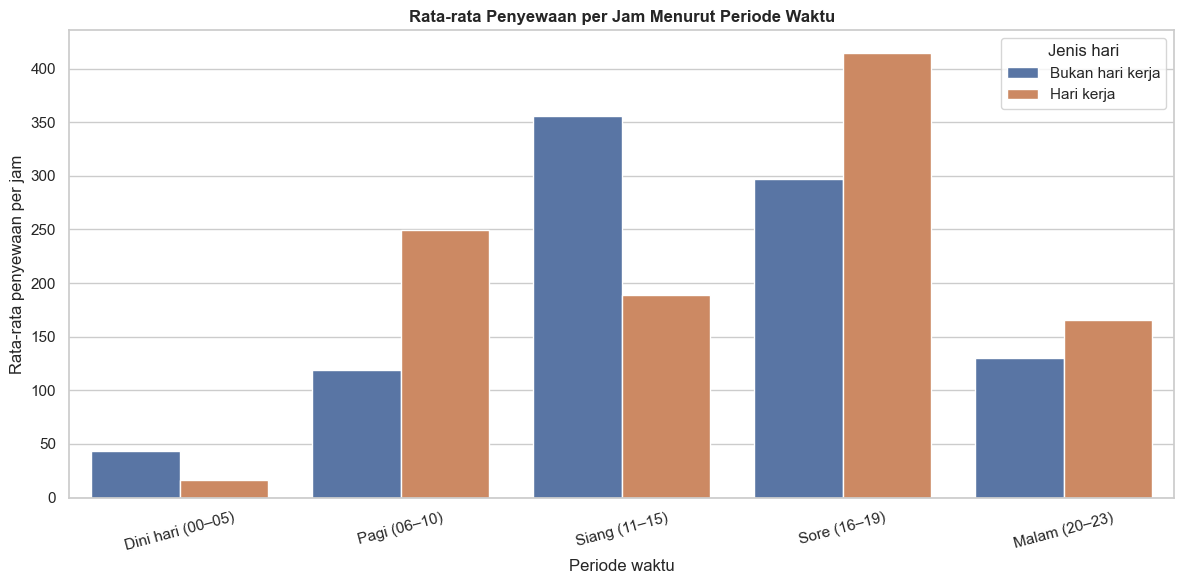

,demand_level,number_of_days,average_daily_rentals,median_daily_rentals,minimum_daily_rentals,maximum_daily_rentals
0,Rendah,244,"2,312.07","2,300.00",22,3740
1,Sedang,243,"4,518.98","4,548.00",3744,5312
2,Tinggi,244,"6,682.07","6,752.00",5312,8714


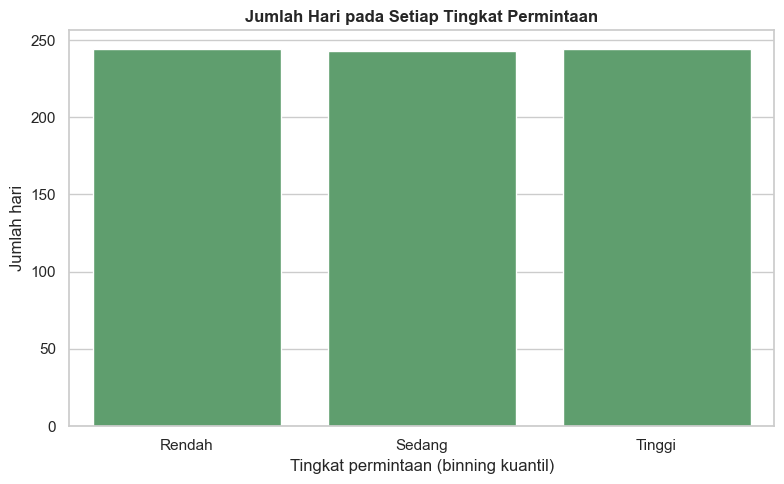

In [27]:
# Manual grouping: mengelompokkan jam ke periode operasional.
time_bins = [-1, 5, 10, 15, 19, 23]
time_labels = [
    "Dini hari (00–05)",
    "Pagi (06–10)",
    "Siang (11–15)",
    "Sore (16–19)",
    "Malam (20–23)",
]
hour_advanced = hour_df.copy()
hour_advanced["time_period"] = pd.cut(
    hour_advanced["hr"],
    bins=time_bins,
    labels=time_labels,
    include_lowest=True,
)

manual_grouping_summary = (
    hour_advanced.groupby(["workingday_label", "time_period"], observed=False)
    .agg(
        average_rentals_per_hour=("cnt", "mean"),
        total_rentals=("cnt", "sum"),
        observed_hour_records=("cnt", "size"),
    )
    .reset_index()
)
display(manual_grouping_summary.round(2))

plt.figure(figsize=(12, 6))
sns.barplot(
    data=manual_grouping_summary,
    x="time_period",
    y="average_rentals_per_hour",
    hue="workingday_label",
)
plt.title("Rata-rata Penyewaan per Jam Menurut Periode Waktu", weight="bold")
plt.xlabel("Periode waktu")
plt.ylabel("Rata-rata penyewaan per jam")
plt.xticks(rotation=15)
plt.legend(title="Jenis hari")
plt.tight_layout()
plt.show()

# Binning: membagi jumlah penyewaan harian menjadi tiga kelompok kuantil.
# Rank(method='first') menjaga qcut tetap dapat membagi data ketika ada nilai berulang.
day_advanced = day_df.copy()
day_advanced["demand_level"] = pd.qcut(
    day_advanced["cnt"].rank(method="first"),
    q=3,
    labels=["Rendah", "Sedang", "Tinggi"],
)

demand_binning_summary = (
    day_advanced.groupby("demand_level", observed=False)
    .agg(
        number_of_days=("cnt", "size"),
        average_daily_rentals=("cnt", "mean"),
        median_daily_rentals=("cnt", "median"),
        minimum_daily_rentals=("cnt", "min"),
        maximum_daily_rentals=("cnt", "max"),
    )
    .reset_index()
)
display(demand_binning_summary.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(
    data=demand_binning_summary,
    x="demand_level",
    y="number_of_days",
    color=sns.color_palette("deep")[2],
)
plt.title("Jumlah Hari pada Setiap Tingkat Permintaan", weight="bold")
plt.xlabel("Tingkat permintaan (binning kuantil)")
plt.ylabel("Jumlah hari")
plt.tight_layout()
plt.show()

### Insight:

Analisis tren bulanan memberikan konteks perkembangan permintaan, sedangkan komposisi pengguna menunjukkan kontribusi pengguna `casual` dan `registered`. Perbandingan tahunan memperlihatkan perubahan skala pemakaian layanan. Manual grouping merangkum rata-rata penyewaan per jam ke dalam periode operasional; binning mengelompokkan 731 hari ke tiga tingkat permintaan berdasarkan kuantil. Kedua teknik ini merupakan segmentasi deskriptif dan tidak memprediksi permintaan masa depan.

## Conclusion & Recommendation

### Conclusion pertanyaan 1

Berdasarkan agregasi rata-rata `cnt` per jam pada `hour.csv`, pola permintaan antara hari kerja dan bukan hari kerja berbeda. Gunakan tabel `peak_table` dan grafik pertanyaan 1 untuk melihat nilai jam puncak beserta rata-rata dan jumlah observasinya. Pada data ini, rata-rata tertinggi hari kerja terjadi pada **pukul 17.00** (sekitar **525,3 penyewaan per jam**), sedangkan pada hari bukan hari kerja terjadi pada **pukul 13.00** (sekitar **372,7 penyewaan per jam**). Dengan demikian, jam operasional prioritas tidak sama untuk kedua jenis hari.

### Conclusion pertanyaan 2

Berdasarkan `day.csv`, rata-rata penyewaan harian tertinggi menurut kategori musim terdapat pada **Fall** (sekitar **5.644,3 penyewaan per hari**; 188 hari pengamatan), sedangkan yang terendah terdapat pada **Spring** (sekitar **2.604,1 penyewaan per hari**; 181 hari pengamatan). Menurut kondisi cuaca, kategori **Clear / Few clouds** memiliki rata-rata tertinggi (sekitar **4.876,8 penyewaan per hari**; 463 hari pengamatan), sedangkan **Light Snow / Light Rain / Thunderstorm** memiliki rata-rata terendah (sekitar **1.803,3 penyewaan per hari**; 21 hari pengamatan). Kategori **Heavy Rain / Snow / Fog** tidak memiliki observasi pada `day.csv`, sehingga tidak dapat dibandingkan pada agregasi harian.

Nama kategori pada kesimpulan ini sama dengan label yang ditampilkan pada tabel dan visualisasi. Jumlah observasi tiap kategori juga perlu diperhatikan, terutama kondisi cuaca **Light Snow / Light Rain / Thunderstorm** yang hanya memiliki 21 hari pengamatan. Perbedaan rata-rata tersebut merupakan pola deskriptif dan tidak membuktikan bahwa musim/cuaca menjadi satu-satunya penyebab perubahan penyewaan.

### Rekomendasi Action Item

1. **Atur kesiapan armada mengikuti jam permintaan.** Prioritaskan pemantauan ketersediaan sepeda menjelang jam sibuk hari kerja, terutama pukul 07.00–08.00 dan 16.00–18.00. Pada bukan hari kerja, pantau peningkatan permintaan menjelang tengah hari hingga sore, khususnya sekitar pukul 12.00–15.00.
2. **Sesuaikan perencanaan kapasitas secara musiman dan berdasarkan cuaca.** Gunakan data historis per kategori sebagai dasar proyeksi kebutuhan, tetapi kombinasikan dengan kalender, suhu, kelembapan, dan kondisi operasional lain sebelum memindahkan armada.
3. **Manfaatkan periode permintaan lebih rendah untuk pemeliharaan terjadwal atau promosi.** Evaluasi efektivitasnya menggunakan perubahan jumlah penyewaan setelah tindakan dilakukan.
4. **Tingkatkan kelengkapan pencatatan per jam.** Selidiki 76 tanggal pada `hour.csv` yang memiliki kurang dari 24 catatan jam. Jangan mengisi catatan yang hilang sebagai nol sebelum penyebab ketidaklengkapan dipastikan.

### Batasan Analisis

- Data hanya mencakup 2011–2012 dan satu sistem bike sharing di Washington, D.C.; hasil tidak otomatis berlaku untuk kota atau periode lain.
- Data per jam memiliki catatan yang tidak lengkap pada sebagian tanggal. Rata-rata per jam dihitung dari observasi yang tersedia.
- Pemetaan kategori mengikuti keterangan pada README dataset. Label ditampilkan dengan nama kategori agar lebih mudah dipahami; kode asli pada dataset tetap dipertahankan.
- Analisis ini bersifat deskriptif, bukan eksperimen kausal.
